In [1]:
import os, re, math
import pandas as pd
from tqdm import tqdm
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_fscore_support, accuracy_score
from sklearn.metrics import roc_curve, auc, precision_recall_fscore_support

/home/bertolo/.local/lib/python3.11/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/bertolo/.local/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
img_fldr = '../images/'

DATA_Order = ['miRNA', 'Toxins (mix)', 'AMR', 'TATA 20-100', 'TATA 1k-3k']

DATA_folders = [
    'tata_n5000_min20_max100',
    'tata_n5000_min1000_max3000',
    'AMR',
    'Toxins_mxd',
    'miRNA',
]

Dir2Meta_cnvtb = {
    'Toxins_mxd':'toxinmix',
    'miRNA': 'mrna',
    'AMR': 'amr',
    'tata_n5000_min20_max100': 'tata_n5000_min20_max100',
    'tata_n5000_min1000_max3000': 'tata_n5000_min1000_max3000'
}

Dir2Lbl_cnvtb = {
    'Toxins_mxd':'tox',
    'miRNA': 'mrna',
    'AMR': 'amr',
    'tata_n5000_min20_max100': 'tata',
    'tata_n5000_min1000_max3000': 'tata'
}

Dir2Title_cnvtb = {
    'Toxins_mxd':'Toxins (mix)',
    'miRNA': 'miRNA',
    'AMR': 'AMR',
    'tata_n5000_min20_max100': 'TATA 20-100',
    'tata_n5000_min1000_max3000': 'TATA 1k-3k'
}

# --- Model name conversion table ---
model_name_map = {
    'evo2_1b_base':  'Evo2 1B Base',
    'evo2_7b':       'Evo2 7B',
    'evo2_20b':       'Evo2 20B',
    'evo2_40b':      'Evo2 40B',
    'evo2_7b_base':  'Evo2 7B Base',
    'evo2_40b_base': 'Evo2 40B Base',
    'medgemma-1.5-4b-it' : 'MedGemma 1.5 4B IT',
    'medgemma-27b-text-it' : 'MedGemma 27B IT txt',
    'gemma-4-31B-it': 'Gemma 4 31B IT',

}

_EVO2_BASE_RE = re.compile(r"evo2.*base", re.IGNORECASE)
_EVO2_RE      = re.compile(r"evo2", re.IGNORECASE)

def get_model_type(model_name: str) -> str:
    """
    Returns:
        "Evo2"  for any Evo2 instruct/chat model
        "Base"  for any Evo2 base model
        "LLM"   for everything else
    """
    if _EVO2_BASE_RE.search(model_name):
        return "Evo 2 Base"
    if _EVO2_RE.search(model_name):
        return "Evo 2 1M"
    return "LLM"

MDL_ORDER = [
    'Evo2 7B', 'Evo2 20B', 'Evo2 40B',
    'MedGemma 1.5 4B IT', 'MedGemma 27B IT txt', 'Gemma 4 31B IT'
]

In [3]:
predictions_rows = []
metadata_rows = []

save_dfs = False
save_fig = True

In [4]:
# --- Select metric weighting system  ---
av = 'macro'

for results_folder_name in DATA_folders:
    results_dir = f'results_ppl_{results_folder_name}/'
    for folder in tqdm(os.listdir(results_dir)):
        folder_path = os.path.join(results_dir, folder)
        if not os.path.isdir(folder_path):
            continue
        if 'DEP' in folder_path:
            continue
    
        # Parse model name and n-shots from folder name e.g. evo2_7b_3shot
        try:
            n_shot = int(folder.split('_')[-1].replace('shot', ''))
            model  = '_'.join(folder.split('_')[:-1])  # everything before _Nshot
            display_model = model_name_map.get(model, model)
        except ValueError:
            print(f"  Skipping unrecognised folder: {folder}")
            continue
        
        # --- predictions.tsv ---
        predictions_path = os.path.join(folder_path, 'predictions.tsv')
        if os.path.exists(predictions_path):
            df = pd.read_csv(predictions_path, sep='\t')

            mdl_nm  = display_model
            mdl_typ = get_model_type(model)
            N       = n_shot
            
            nll_scores = df[['nll_class0', 'nll_class1']].values.astype(float)
            log_probs   = -nll_scores                                           # (N, 2)
            log_probs  -= log_probs.max(axis=1, keepdims=True)                  # numerical stability
            probs       = np.exp(log_probs)
            probs      /= probs.sum(axis=1, keepdims=True)                      # proper probabilities
        
            pos_label = Dir2Lbl_cnvtb[results_folder_name]
            CLASS_NAMES = [pos_label, 'neutral']   # must match script definition
            pos_class_idx = CLASS_NAMES.index(pos_label)   # 0 or 1
            prob_pos      = probs[:, pos_class_idx]        # score for the positive class
        
            fpr, tpr, thresholds = roc_curve(
                df['true_class'].astype(int),
                prob_pos,
                pos_label=pos_class_idx,   # integer, consistent with true_class dtype
            )
            auc_score = auc(fpr, tpr)
        
            precision, recall, f1, _ = precision_recall_fscore_support(
                df['true_class'].astype(int),
                df['pred_class'].astype(int),
                average='macro',
                zero_division=0,
            )

            predictions_rows.append([
                mdl_nm, mdl_typ, N, Dir2Title_cnvtb[results_folder_name],
                precision, recall, f1, auc_score
            ])

        test_metadata = pd.read_csv(f'data/{Dir2Meta_cnvtb[results_folder_name]}_test_metadata.tsv', sep='\t')
        train_metadata = pd.read_csv(f'data/{Dir2Meta_cnvtb[results_folder_name]}_train_metadata.tsv', sep='\t')

        test_metadata['split'] = ['Test'] * len(test_metadata)
        train_metadata['split'] = ['Train'] * len(train_metadata)
        
        lcl_metadata_df = pd.concat([test_metadata, train_metadata])
        lcl_metadata_df['Data'] = [Dir2Title_cnvtb[results_folder_name]] * len(lcl_metadata_df)
        metadata_rows.append(lcl_metadata_df)

# --- Build final dataframes ---
predictions_df = pd.DataFrame(
    predictions_rows,
    columns=(['Model', 'Type', 'N', 'Data', 'Precision', 'Recall', 'F1', 'AUC'])
)

metadata_df = pd.concat(metadata_rows).reset_index(drop=True)
metadata_df['Label'] = ['Neutral' if l == 'neutral' else 'Target' for l in metadata_df.label]

100%|██████████████████████████████████████████| 16/16 [00:00<00:00, 132.18it/s]


  Skipping unrecognised folder: .ipynb_checkpoints


 85%|████████████████████████████████████▌      | 17/20 [00:00<00:00, 49.53it/s]

  Skipping unrecognised folder: .ipynb_checkpoints


100%|██████████████████████████████████████████| 39/39 [00:00<00:00, 134.00it/s]


  Skipping unrecognised folder: .ipynb_checkpoints


 17%|███████▎                                   | 12/71 [00:00<00:02, 23.54it/s]

  Skipping unrecognised folder: .ipynb_checkpoints


100%|███████████████████████████████████████████| 71/71 [00:03<00:00, 21.53it/s]


In [5]:
predictions_df.sample(5)

,Model,Type,N,Data,Precision,Recall,F1,AUC
75,Evo2 7B,Evo 2 1M,16,Toxins (mix),0.679386,0.671820,0.658222,0.742163
48,Evo2 40B,Evo 2 1M,1,TATA 1k-3k,0.512016,0.512000,0.511842,0.508578
133,Evo2 7B,Evo 2 1M,128,miRNA,0.900737,0.890851,0.890174,0.953934
30,Gemma 4 31B IT,LLM,2,TATA 20-100,0.480998,0.481000,0.480987,0.481644
80,Evo2 40B,Evo 2 1M,4,Toxins (mix),0.533331,0.533486,0.530007,0.540850


Saved evo2_icl_fulldata_f1hm.png


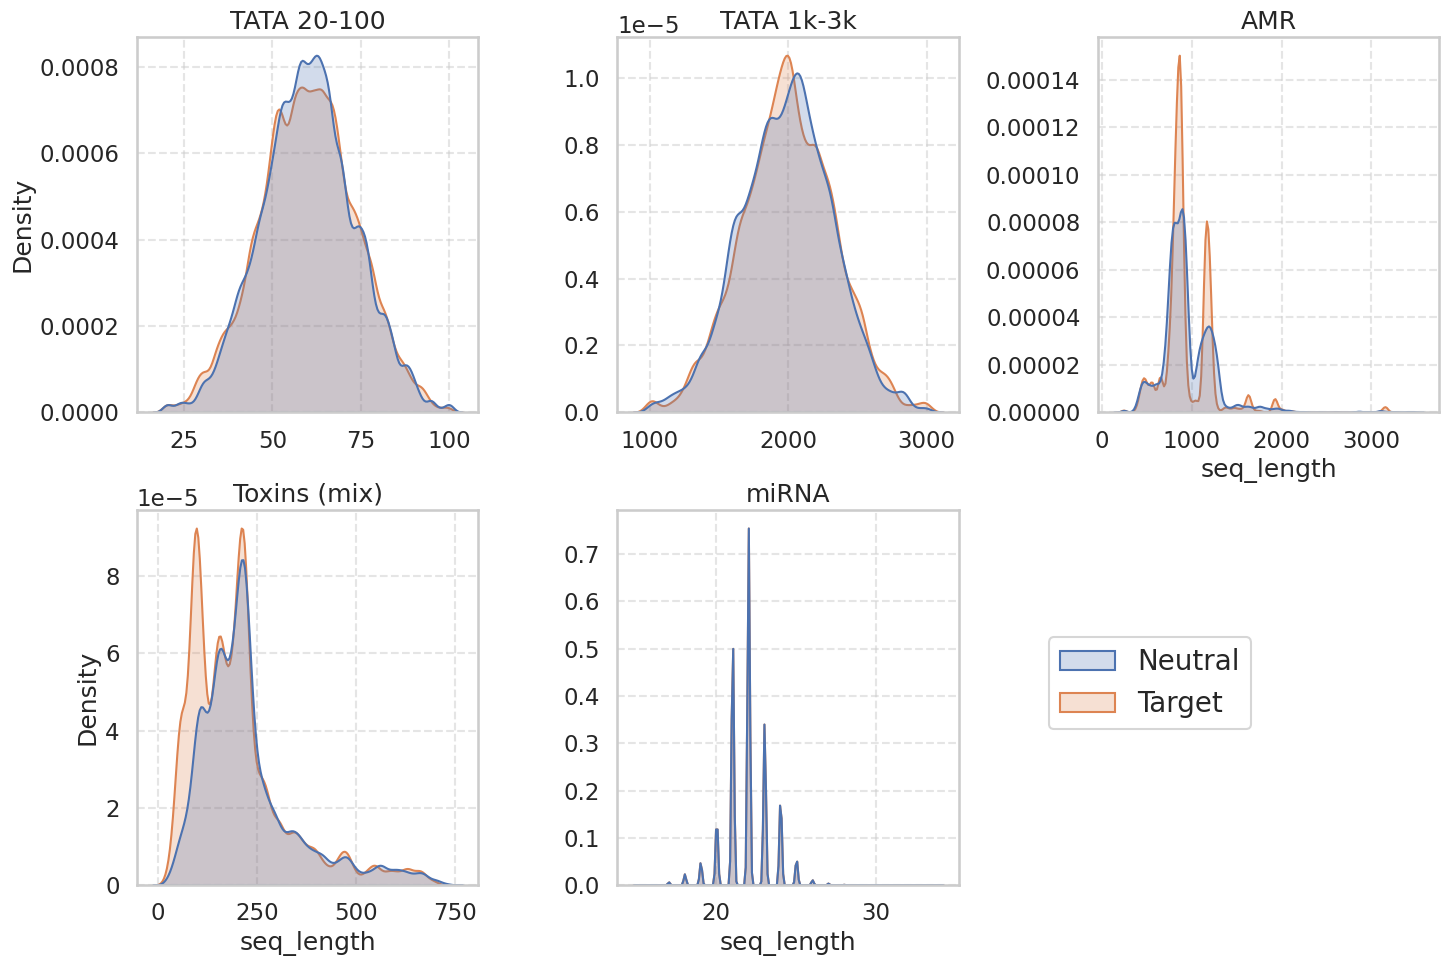

In [6]:
# --- Select style system  ---
sns.set('talk', 'whitegrid')

g = sns.displot(
    data=metadata_df,
    x='seq_length',
    facet_kws={'sharex':False, 'sharey':False},
    kind="kde",
    col='Data',
    col_wrap=3,
    hue='Label',
    fill=True,
)

g.set_titles('{col_name}')

sns.move_legend(
    g,
    "center",
    bbox_to_anchor=(.7, .3),
    frameon=True,
    title=None,
    ncol=1,
    fontsize=20,
)

for ax in g.axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)

if save_fig:
    plt.savefig(f'images/evo2_icl_data_dist.png', dpi=150, bbox_inches='tight')
    plt.savefig(f'{img_fldr}/evo2_icl_data_dist.png', dpi=150, bbox_inches='tight')
    print("Saved evo2_icl_fulldata_f1hm.png")

plt.show()

In [7]:
predictions_df_pivoted = predictions_df.melt(
    id_vars=['Model', 'Type', 'N', 'Data'],
    value_vars=['Precision', 'Recall', 'F1', 'AUC'],
    var_name='Metric',
    value_name='Score'
)

# Find best model-n combo per Data based on F1
best_idx = (
    predictions_df.groupby(['Data', 'Model'])['F1']
    .idxmax()
)

df_best = predictions_df.loc[best_idx, ['Model', 'Type', 'N', 'Data', 'Precision', 'Recall', 'F1', 'AUC']].reset_index(drop=True)

# Then melt as before
df_best_pivoted = df_best.melt(
    id_vars=['Model', 'Type', 'N', 'Data'],
    value_vars=['Precision', 'Recall', 'F1', 'AUC'],
    var_name='Metric',
    value_name='Score'
)

In [8]:
df_best_pivoted.sample(5)

,Model,Type,N,Data,Metric,Score
73,MedGemma 1.5 4B IT,LLM,16,Toxins (mix),F1,0.526769
20,Evo2 20B,Evo 2 1M,128,miRNA,Precision,0.846205
53,Gemma 4 31B IT,LLM,128,miRNA,Recall,0.586322
35,MedGemma 27B IT txt,LLM,1,TATA 1k-3k,Recall,0.505000
82,MedGemma 1.5 4B IT,LLM,128,miRNA,F1,0.634057


saved at: /eos/jeodpp/data/projects/DIGLIFE/bertolo/images//evo2_icl_fulldata_f1hm.png


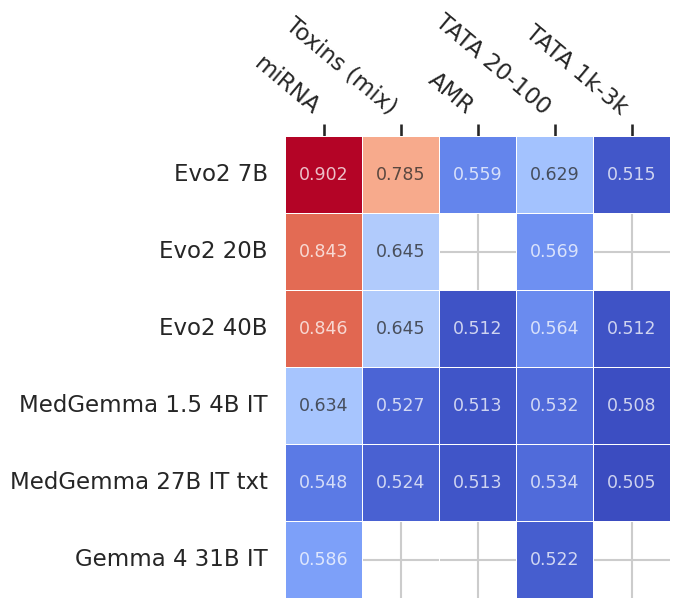

ImportError: Pandas requires version '3.1.5' or newer of 'jinja2' (version '3.1.4' currently installed).

In [9]:
# Pivot: Model as index, Data as columns
lcl_df = df_best_pivoted[
    ~df_best_pivoted['Type'].isin(['Evo 2 Base']) & 
    df_best_pivoted['Metric'].isin(['F1'])
]

df_pivot = lcl_df.pivot_table(
    index='Model',
    columns='Data',
    values='Score'
)

df_pivot.columns.name = None  # remove 'Data' label above columns
df_pivot.index.name = None    # remove 'Model' label

df_pivot_ordered = df_pivot[DATA_Order]
df_pivot_ordered = df_pivot_ordered.loc[MDL_ORDER]

# --- Select style system  ---
sns.set('talk', 'whitegrid')

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    df_pivot_ordered,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',#'crest'
    ax=ax,
    linewidths=0.5,
    cbar=False,
    square=True,
    annot_kws={'size': 'x-small', 'alpha': 0.75},
#    vmin=0., vmax=1.,
)

ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
plt.xticks(rotation=320, ha='right')  # ha='left' aligns correctly when on top

if save_fig:
    plt.savefig(f'images/evo2_icl_fulldata_f1hm.png', dpi=150, bbox_inches='tight')
    plt.savefig(f'{img_fldr}/evo2_icl_fulldata_f1hm.png', dpi=150, bbox_inches='tight')
    print(f'saved at: {img_fldr}/evo2_icl_fulldata_f1hm.png')

plt.show()

print(df_pivot_ordered.to_latex(float_format="%.3f", na_rep='-'))

Saved evo2_icl_fulldata_barplot.png


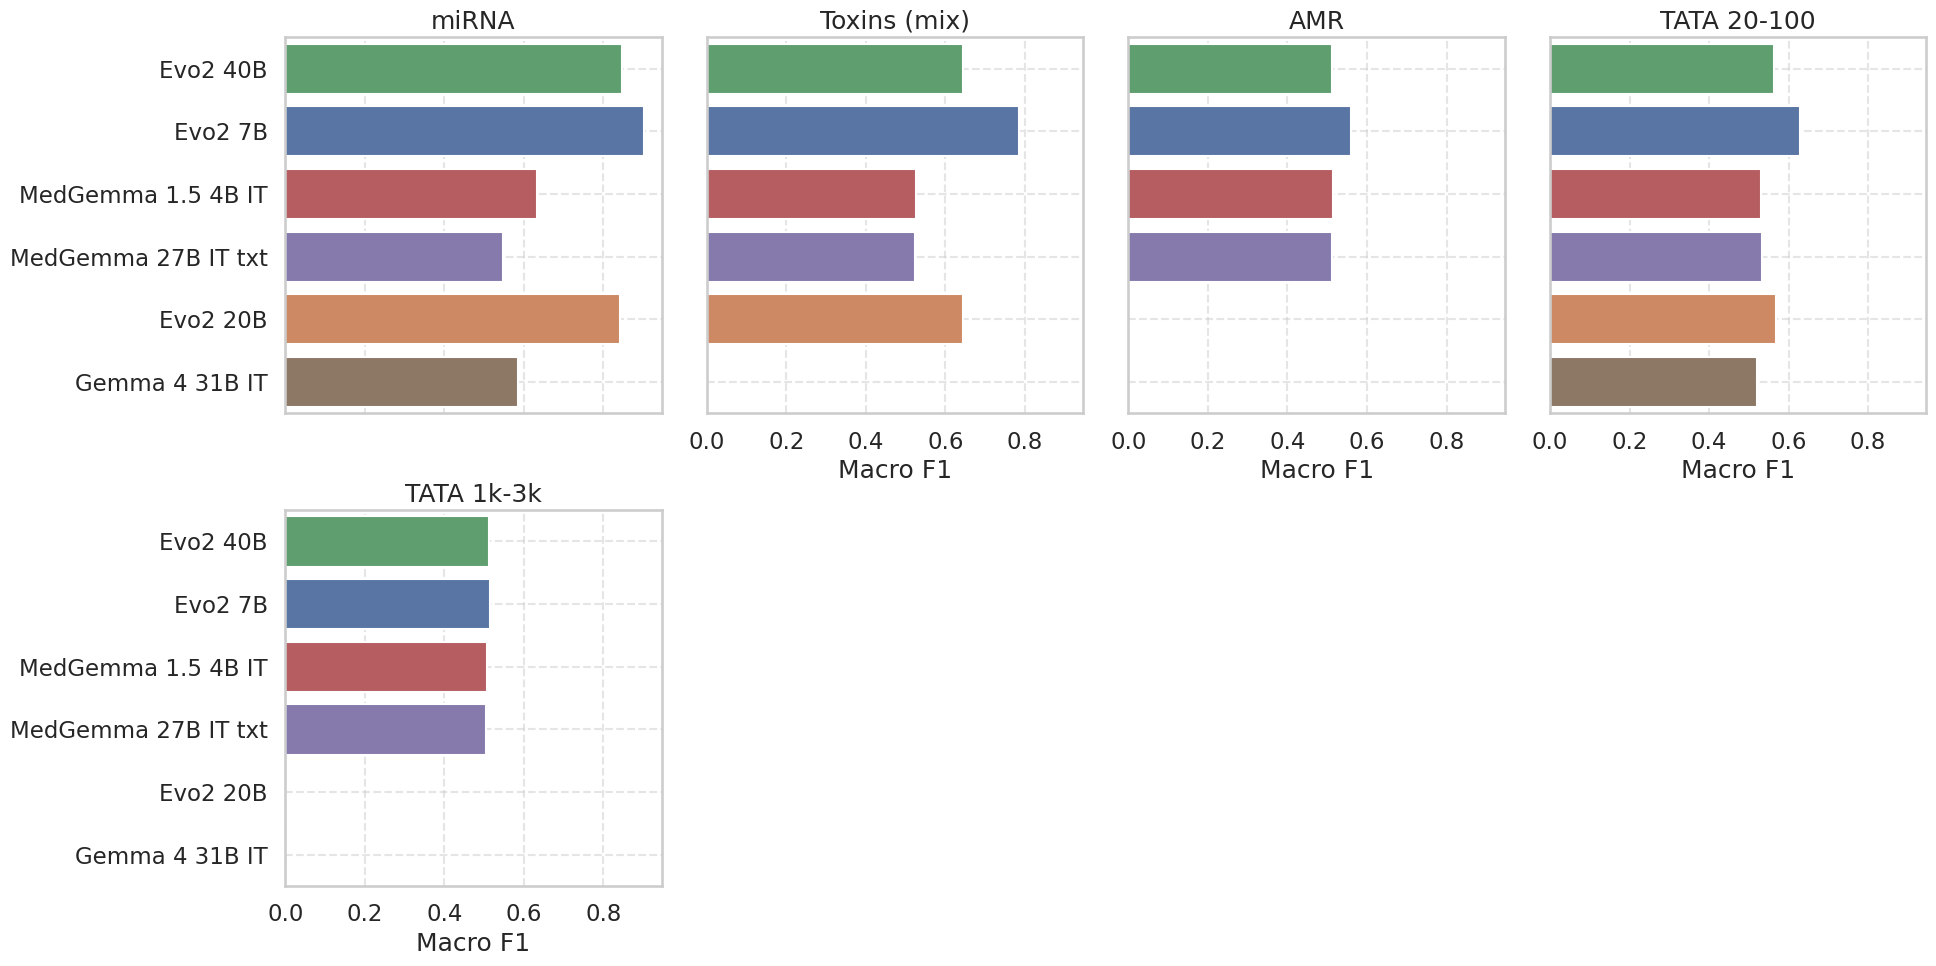

In [10]:
# --- Select style system  ---
sns.set('talk', 'whitegrid')

g = sns.catplot(
    data=df_best_pivoted[~df_best_pivoted['Type'].isin(['Evo 2 Base']) & df_best_pivoted['Metric'].isin(['F1'])],
    y='Model',
    x='Score',
    hue='Model',
    col='Data',
    col_wrap=4,
    kind='bar',
    hue_order=MDL_ORDER,
    col_order=DATA_Order,
)

for ax in g.axes.flat:
    ax.grid(True, linestyle='--', alpha=0.5)
    for spine in ax.spines.values():
        spine.set_visible(True)
    # plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

g.set(xlabel='Macro F1', ylabel='')
g.set_titles('{col_name}')

if save_fig:
    plt.savefig(f'images/evo2_icl_fulldata_barplot.png', dpi=150, bbox_inches='tight')
    plt.savefig(f'{img_fldr}/evo2_icl_fulldata_barplot.png', dpi=150, bbox_inches='tight')
    print("Saved evo2_icl_fulldata_barplot.png")

plt.show()

In [11]:
# --- Select style system  ---
sns.set('poster', 'whitegrid')


def plot_metric_heatmaps(df, col_num=2, figsize_per_cell=(6, 5), save_path=None, cbar=True):
    """
    df: expects columns [Model, Data, Metric, Score]
    """
    data_splits = df['Data'].unique()
    n_splits = len(data_splits)
    n_cols = min(col_num, n_splits)
    n_rows = math.ceil(n_splits / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(figsize_per_cell[0] * n_cols, figsize_per_cell[1] * n_rows))
    axes = np.array(axes).flatten()

    for i, data in enumerate(data_splits):
        ax = axes[i]
        df_sub = df[df['Data'] == data].pivot(index='Model', columns='Metric', values='Score')

        sns.heatmap(df_sub, annot=True, fmt='.3f', o
                    cmap='coolwarm', ax=ax, cbar=cbar,
                    mask=df_sub.isnull(), linewidths=0.5,
                    square=True, annot_kws={'alpha': 0.75})
        ax.patch.set_facecolor('#d3d3d3')
        ax.set_title(f'{data}')
        ax.set_xlabel('')
        ax.set_ylabel('')

    for ax in axes[n_splits:]:
        ax.set_visible(False)

    plt.suptitle('Metrics by Model and Data Split', fontsize=13)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

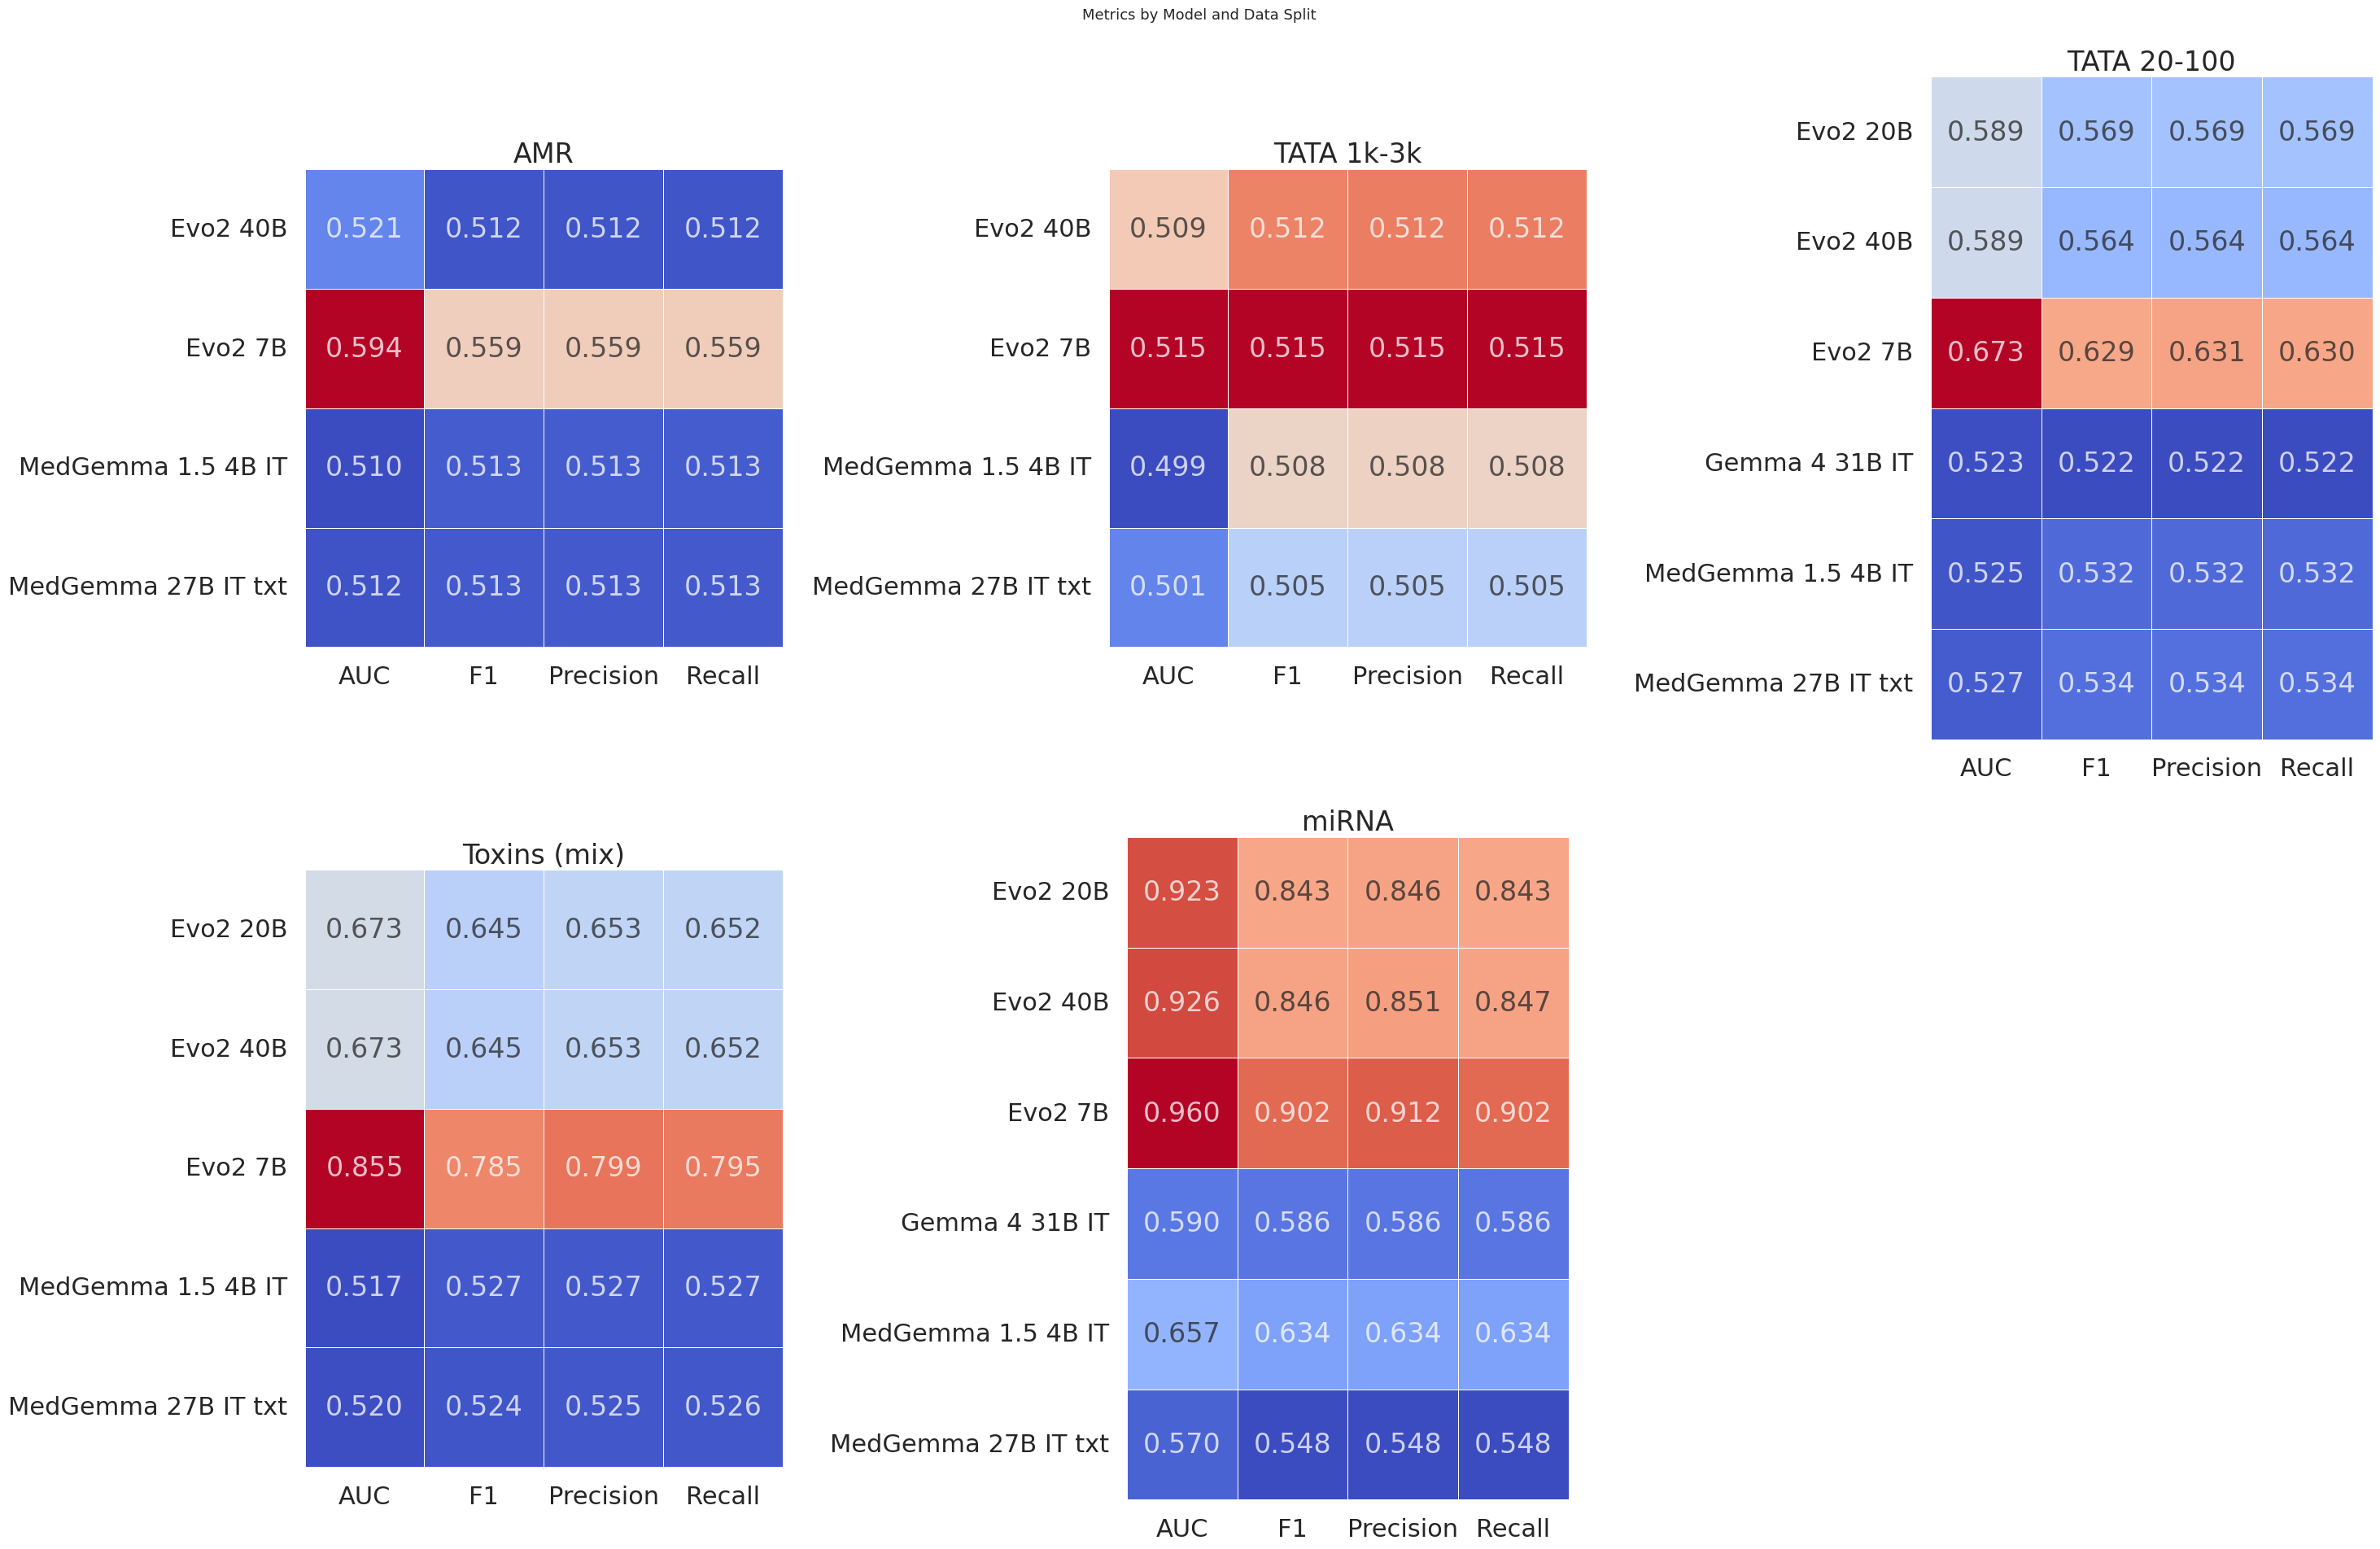

In [12]:
plot_metric_heatmaps(
    df_best_pivoted[df_best_pivoted.Type!='Evo 2 Base'], 
    col_num=3, figsize_per_cell=(10, 9.8),
    save_path=f'{img_fldr}/evo2_icl_fulldata_heatmap.png',
    cbar=False,
)